# EV Energy Consumption Prediction — Milestone 3
## EDA, Business Insights, Feature Engineering, and Preprocessing

**Goal:** prepare the EV energy-consumption dataset for regression modeling.

**Important decisions**
- `Energy_Consumption_kWh` is the target variable.
- `Vehicle_ID` is an identifier, so it is not used as a predictive feature.
- `Timestamp` is used to order the data chronologically and create time features, then the raw timestamp is removed.
- The coded columns `Driving_Mode`, `Road_Type`, `Traffic_Condition`, and `Weather_Condition` are categorical, even though they are stored as integers.
- The data is split chronologically before fitting encoders or scalers to reduce leakage from future records into earlier records.
- We will inspect outliers, but will not automatically delete valid extreme observations without a domain reason.

## 1. Import libraries and load the dataset

In [1]:
# Import pandas for data manipulation and NumPy for numerical operations.
import pandas as pd
import numpy as np

# Import Matplotlib and Seaborn for visual exploration.
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for preprocessing and a leak-safe machine-learning pipeline.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Set a consistent style for readable charts.
# Use Matplotlib default styling for robust plotting.

# Load the CSV file. Keep the CSV in the same folder as this notebook,
# or replace the path below with the correct file path.
df = pd.read_csv("EV_Energy_Consumption(2).csv")

# Display a preview to confirm that the file loaded correctly.
display(df.head())

Matplotlib is building the font cache; this may take a moment.


,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
0,1102,2024-01-01 00:00:00,111.507366,-2.773816,30.415148,378.091525,25.314786,2,1,1,6.879446,4,0.741770,42.172533,7.829253,31.112020,1822.967368,20.757508,12.054317
1,1435,2024-01-01 00:01:00,48.612323,-0.796982,97.385534,392.718377,18.240755,1,2,1,-3.007212,4,-3.495516,57.018427,4.495572,31.504366,2091.831914,0.642918,4.488701
2,1860,2024-01-01 00:02:00,108.733320,0.253800,84.912600,398.993495,44.449145,1,1,3,0.029585,1,9.248275,69.028911,5.144489,33.838015,1816.702497,40.842824,11.701377
3,1270,2024-01-01 00:03:00,38.579484,-2.111395,28.777904,358.128273,28.980155,1,2,2,8.271943,3,2.868409,86.638349,4.518283,33.256014,1283.102642,5.305229,7.389266
4,1106,2024-01-01 00:04:00,57.172438,1.477883,29.740160,310.888162,33.184551,2,1,1,2.776814,2,16.750244,27.189185,4.263406,33.579678,2160.350788,5.825926,6.761205


## 2. Inspect the dataset

In [2]:
# Check the number of rows and columns.
print("Dataset shape:", df.shape)

# Review column names and data types.
df.info()

# Count missing values in every column.
print("\\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing_Count"))

# Count exact duplicate rows.
print("Exact duplicate rows:", df.duplicated().sum())

# Show descriptive statistics for numeric columns.
display(df.describe().T)

Dataset shape: (5000, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Vehicle_ID              5000 non-null   int64  
 1   Timestamp               5000 non-null   object 
 2   Speed_kmh               5000 non-null   float64
 3   Acceleration_ms2        5000 non-null   float64
 4   Battery_State_%         5000 non-null   float64
 5   Battery_Voltage_V       5000 non-null   float64
 6   Battery_Temperature_C   5000 non-null   float64
 7   Driving_Mode            5000 non-null   int64  
 8   Road_Type               5000 non-null   int64  
 9   Traffic_Condition       5000 non-null   int64  
 10  Slope_%                 5000 non-null   float64
 11  Weather_Condition       5000 non-null   int64  
 12  Temperature_C           5000 non-null   float64
 13  Humidity_%              5000 non-null   float64
 14  Wind_Speed_ms 

,Missing_Count
Vehicle_ID,0
Timestamp,0
Speed_kmh,0
Acceleration_ms2,0
Battery_State_%,0
Battery_Voltage_V,0
Battery_Temperature_C,0
Driving_Mode,0
Road_Type,0
Traffic_Condition,0


Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Vehicle_ID,5000.0,1505.701200,290.836902,1000.000000,1253.000000,1510.000000,1761.000000,1999.000000
Speed_kmh,5000.0,59.312952,34.517605,0.001396,29.515400,58.646794,89.030001,119.946924
Acceleration_ms2,5000.0,-0.019885,1.724287,-2.999683,-1.490240,-0.043329,1.473887,2.998039
Battery_State_%,5000.0,60.214465,23.128262,20.020196,40.088318,60.490283,80.409928,99.993986
Battery_Voltage_V,5000.0,351.118306,28.968372,300.004812,326.613439,351.510915,375.968140,399.990098
Battery_Temperature_C,5000.0,27.510130,10.015385,10.003858,18.884742,27.581710,35.920162,44.985943
Driving_Mode,5000.0,2.011000,0.810068,1.000000,1.000000,2.000000,3.000000,3.000000
Road_Type,5000.0,1.999200,0.808536,1.000000,1.000000,2.000000,3.000000,3.000000
Traffic_Condition,5000.0,2.010800,0.812167,1.000000,1.000000,2.000000,3.000000,3.000000
Slope_%,5000.0,2.504690,4.360854,-4.991079,-1.235653,2.452368,6.366990,9.998358


## 3. Clean basic data issues

In [3]:
# Work on a copy so the original loaded DataFrame remains unchanged.
df_clean = df.copy()

# Remove exact duplicate rows if any exist.
# Duplicates can give repeated observations extra influence during modeling.
df_clean = df_clean.drop_duplicates().copy()

# Parse Timestamp into datetime values.
# errors='coerce' converts invalid timestamps to NaT so they can be counted.
df_clean["Timestamp"] = pd.to_datetime(df_clean["Timestamp"], errors="coerce")

# Report timestamp values that could not be parsed.
print("Invalid timestamps:", df_clean["Timestamp"].isna().sum())

# Remove rows without a valid timestamp because chronological splitting
# depends on the timestamp being available.
df_clean = df_clean.dropna(subset=["Timestamp"]).copy()

# Show the updated shape after basic cleaning.
print("Shape after basic cleaning:", df_clean.shape)

Invalid timestamps: 0
Shape after basic cleaning: (5000, 19)


## 4. Define the target and understand categorical columns

In [4]:
# Define the target that the regression model will predict.
target = "Energy_Consumption_kWh"

# These columns contain category codes, not continuous measurements.
categorical_columns = [
    "Driving_Mode",
    "Road_Type",
    "Traffic_Condition",
    "Weather_Condition",
]

# Print the values in each categorical column.
# The dataset does not provide a codebook here, so do not guess what each code means.
for column in categorical_columns:
    print(f"\\n{column} values:")
    print(df_clean[column].value_counts(dropna=False).sort_index())

\nDriving_Mode values:
Driving_Mode
1    1613
2    1719
3    1668
Name: count, dtype: int64
\nRoad_Type values:
Road_Type
1    1636
2    1732
3    1632
Name: count, dtype: int64
\nTraffic_Condition values:
Traffic_Condition
1    1622
2    1702
3    1676
Name: count, dtype: int64
\nWeather_Condition values:
Weather_Condition
1    1260
2    1279
3    1245
4    1216
Name: count, dtype: int64


## 5. Exploratory Data Analysis (EDA)

ValueError: Invalid RGBA argument: None

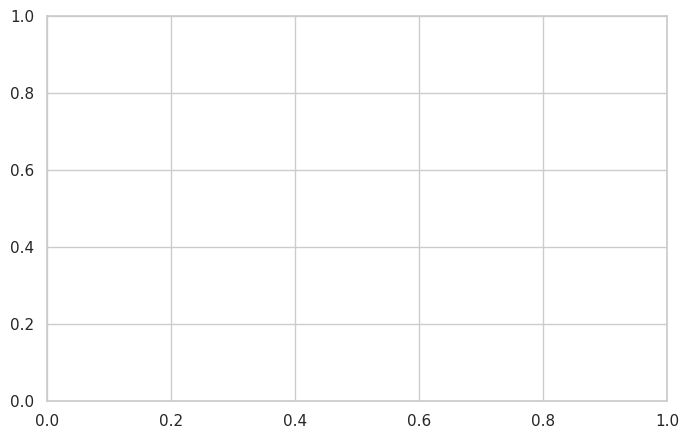

In [5]:
# Plot the distribution of the target variable.
plt.figure(figsize=(8, 5))
plt.hist(df_clean[target].dropna(), bins=30, edgecolor="black", color="steelblue")
plt.title("Distribution of EV Energy Consumption")
plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

# A histogram helps us see the typical range, spread, and skew of the target.

In [ ]:
# Compare energy consumption across each coded categorical feature.
# The labels are shown as codes because the dataset does not include a codebook.
for column in categorical_columns:
    plt.figure(figsize=(8, 5))
    plt.boxplot([df_clean.loc[df_clean[column] == category, target].dropna() for category in sorted(df_clean[column].dropna().unique())], tick_labels=sorted(df_clean[column].dropna().unique()), patch_artist=False)
    plt.title(f"Energy Consumption by {column} category")
    plt.xlabel(f"{column} (category code)")
    plt.ylabel("Energy Consumption (kWh)")
    plt.tight_layout()
    plt.show()

# These plots show differences in distributions between categories.
# Differences are descriptive and do not prove that a category causes consumption changes.

In [ ]:
# Visualize relationships between selected continuous features and the target.
numeric_to_plot = [
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Temperature_C",
    "Slope_%",
    "Temperature_C",
    "Distance_Travelled_km",
]

for column in numeric_to_plot:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df_clean, x=column, y=target, alpha=0.45, color="steelblue")
    plt.title(f"{column} vs. Energy Consumption")
    plt.xlabel(column)
    plt.ylabel("Energy Consumption (kWh)")
    plt.tight_layout()
    plt.show()

# Scatter plots help reveal possible trends, non-linear patterns, and unusual observations.

## 6. Correlation analysis

In [ ]:
# Calculate correlations only for continuous numeric measurements and the target.
# Category codes are excluded because their numeric codes do not necessarily represent magnitude.
continuous_columns = [
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Voltage_V",
    "Battery_Temperature_C",
    "Slope_%",
    "Temperature_C",
    "Humidity_%",
    "Wind_Speed_ms",
    "Tire_Pressure_psi",
    "Vehicle_Weight_kg",
    "Distance_Travelled_km",
    target,
]

correlation_matrix = df_clean[continuous_columns].corr(numeric_only=True)

plt.figure(figsize=(12, 9))
image = plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(image, label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
for row in range(len(correlation_matrix.index)):
    for col in range(len(correlation_matrix.columns)):
        plt.text(col, row, f"{correlation_matrix.iloc[row, col]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlation Heatmap: Continuous Features and Target")
plt.tight_layout()
plt.show()

# Correlation describes linear association, not causation.
# A weak linear correlation does not rule out a non-linear relationship.

In [ ]:
# Rank features by their correlation with the target.
target_correlations = (
    correlation_matrix[target]
    .drop(target)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

display(target_correlations.to_frame("Correlation_with_Target"))

# Use the values from this table and the plots to write evidence-based business insights.
# Do not claim a relationship is strong unless the observed values support that conclusion.

## 7. Outlier inspection (do not delete automatically)

In [ ]:
# Use the IQR rule to flag potential outliers in continuous numeric columns.
# A flagged point is not automatically an error; it needs domain investigation.
outlier_rows = []

for column in continuous_columns:
    if column == target:
        # Include the target in the inspection as well.
        pass

    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = ((df_clean[column] < lower_bound) | (df_clean[column] > upper_bound)).sum()

    outlier_rows.append({
        "Column": column,
        "Lower_IQR_Bound": lower_bound,
        "Upper_IQR_Bound": upper_bound,
        "Potential_Outlier_Count": int(count),
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

# We report potential outliers rather than dropping them automatically.
# Remove or cap values only when there is a justified data-quality or domain reason.

## 8. Feature engineering

In [ ]:
# Create time-based features from Timestamp.
# Hour can capture time-of-day patterns; day of week can capture weekday/weekend patterns.
df_clean["Hour_of_Day"] = df_clean["Timestamp"].dt.hour
df_clean["Day_of_Week"] = df_clean["Timestamp"].dt.dayofweek

# Sort rows by time before splitting.
# This makes the test set represent later observations than the training set.
df_clean = df_clean.sort_values("Timestamp").reset_index(drop=True)

# Do not use Vehicle_ID as a predictor because it is an identifier rather than a driving condition.
# Keep the original Timestamp only for ordering and then remove it from model features.
print("Added features: Hour_of_Day, Day_of_Week")
display(df_clean[["Timestamp", "Hour_of_Day", "Day_of_Week", target]].head())

## 9. Prepare features and split chronologically

In [ ]:
# Separate the target from the input features.
# Drop the target, identifier, and raw timestamp from X.
X = df_clean.drop(columns=[target, "Vehicle_ID", "Timestamp"])
y = df_clean[target].copy()

# Treat the engineered time features as categorical for one-hot encoding.
# This avoids pretending that the difference between hour 23 and hour 0 is 23 units.
categorical_features = categorical_columns + ["Hour_of_Day", "Day_of_Week"]

# All remaining input columns are continuous numeric features.
numeric_features = [column for column in X.columns if column not in categorical_features]

# Split chronologically: first 80% for training, last 20% for testing.
# No shuffle is used because timestamps form an ordered sequence.
split_index = int(len(df_clean) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Confirm the time ranges do not overlap.
print("Training time range:", df_clean["Timestamp"].iloc[0], "to", df_clean["Timestamp"].iloc[split_index - 1])
print("Testing time range:", df_clean["Timestamp"].iloc[split_index], "to", df_clean["Timestamp"].iloc[-1])

## 10. Build a preprocessing pipeline (fit on training data only)

In [ ]:
# Numeric pipeline:
# 1) Fill missing numeric values with the training-set median.
# 2) Standardize features using the training-set mean and standard deviation.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical pipeline:
# 1) Fill missing categories with the most frequent training category.
# 2) One-hot encode categories so the model does not treat category codes as ordered quantities.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Apply each pipeline to its appropriate columns.
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# Fit the preprocessing steps ONLY on the training set.
# Transform the test set using the already-fitted training transformations.
X_train_processed_array = preprocessor.fit_transform(X_train)
X_test_processed_array = preprocessor.transform(X_test)

# Get readable feature names after scaling and one-hot encoding.
feature_names = preprocessor.get_feature_names_out()

# Convert transformed arrays back to DataFrames for inspection and export.
X_train_processed = pd.DataFrame(
    X_train_processed_array, columns=feature_names, index=X_train.index
)
X_test_processed = pd.DataFrame(
    X_test_processed_array, columns=feature_names, index=X_test.index
)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
display(X_train_processed.head())

## 11. Final readiness checks

In [ ]:
# Check that all processed input features are numeric.
print("All training features numeric:", all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train_processed.dtypes))
print("All testing features numeric:", all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_test_processed.dtypes))

# Check for missing values after preprocessing.
print("Missing values in processed train:", int(X_train_processed.isna().sum().sum()))
print("Missing values in processed test:", int(X_test_processed.isna().sum().sum()))

# Confirm that training and testing indices do not overlap.
overlap = set(X_train_processed.index).intersection(set(X_test_processed.index))
print("Train/test index overlap:", len(overlap))

# Verify target values are aligned to their corresponding feature rows.
print("Train feature/target rows match:", len(X_train_processed) == len(y_train))
print("Test feature/target rows match:", len(X_test_processed) == len(y_test))

# Display a compact summary of the final dataset sizes.
readiness_summary = pd.DataFrame({
    "Dataset": ["X_train_processed", "X_test_processed", "y_train", "y_test"],
    "Rows": [len(X_train_processed), len(X_test_processed), len(y_train), len(y_test)],
    "Columns": [X_train_processed.shape[1], X_test_processed.shape[1], 1, 1],
})
display(readiness_summary)

## 12. Export the processed datasets

In [ ]:
# Save processed features and targets as separate files.
# This keeps the target separate from input features and makes the split explicit.
X_train_processed.to_csv("X_train_processed.csv", index=False)
X_test_processed.to_csv("X_test_processed.csv", index=False)
y_train.to_frame(target).to_csv("y_train.csv", index=False)
y_test.to_frame(target).to_csv("y_test.csv", index=False)

# Also save a cleaned copy with engineered time features for EDA/documentation.
# This is not the scaled model matrix; it is a cleaned, interpretable dataset.
df_clean.to_csv("EV_Energy_Consumption_cleaned_for_EDA.csv", index=False)

print("Export complete.")

## 13. How to write business insights

After running the notebook, use the actual chart and correlation results to complete statements such as:

- **Target distribution:** describe the typical energy-consumption range and whether the distribution appears skewed.
- **Feature relationship:** name a feature only if its scatter plot or correlation value supports the claim; describe the relationship as an association, not proof of causation.
- **Categorical comparison:** compare the distributions across category codes, without assigning meanings to codes unless you have the dataset's codebook.
- **Outliers:** report the number of potential IQR outliers and explain that they were inspected rather than automatically removed.

## Final note
This notebook prepares the data for modeling but does not train or evaluate a regression model, because Milestone 3 is the checkpoint before model training. When the dataset owner provides a codebook, replace category codes with documented labels for clearer charts and presentation.